In [6]:
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download("vader_lexicon")
sia = SentimentIntensityAnalyzer()
df = pd.read_csv("../data/processed/cleaned_reviews.csv")
sia.polarity_scores(df["review_text"][0])

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\jyoti\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


{'neg': 0.0, 'neu': 0.733, 'pos': 0.267, 'compound': 0.3716}

In [7]:
df["compound"] = df["review_text"].apply(lambda t: sia.polarity_scores(t)["compound"])

In [8]:
def label(score):
    if score >= 0.05:
        return ("positive")
    elif score <=-0.05:
        return ("negative")
    else:
        return ("neutral")

df["sentiment"] = df["compound"].apply(label)

In [9]:
df["sentiment"].value_counts()

sentiment
positive    32
neutral      9
negative     9
Name: count, dtype: int64

In [10]:
df[["review_text", "compound", "sentiment"]]

,review_text,compound,sentiment
0,Sound quality is great but battery drains fast,0.3716,positive
1,Very comfortable and clear sound,0.7548,positive
2,Good design but connectivity drops sometimes,0.2382,positive
3,Overpriced for what you get,0.0000,neutral
4,Broke within a month,-0.4215,negative
5,Good bass for the price,0.4404,positive
6,Excellent sound quality and long battery life,0.5719,positive
7,Comfortable fit but case feels cheap,0.4404,positive
8,Average sound quality for daily use,0.0000,neutral
9,Battery life is disappointing,-0.4939,negative


In [11]:
df["compound"] = df["review_text"].apply(lambda t: sia.polarity_scores(t)["compound"])

In [12]:
human = ["neutral","positive","neutral","negative","negative","positive",
         "positive","neutral","neutral","negative","positive","positive",
         "neutral","positive","positive","negative","positive","negative"]

sample = df.iloc[:18].copy()
sample["human_label"] = human
(sample["human_label"] == sample["sentiment"]).mean()

np.float64(0.6666666666666666)

In [13]:
sample[sample["human_label"] != sample["sentiment"]][["review_text","human_label","sentiment"]]

,review_text,human_label,sentiment
0,Sound quality is great but battery drains fast,neutral,positive
2,Good design but connectivity drops sometimes,neutral,positive
3,Overpriced for what you get,negative,neutral
7,Comfortable fit but case feels cheap,neutral,positive
12,Sound is good but earbuds fall out easily,neutral,positive
13,Lightweight design and decent battery,positive,neutral


In [14]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(sample["human_label"], sample["sentiment"]))


              precision    recall  f1-score   support

    negative       1.00      0.80      0.89         5
     neutral       0.33      0.20      0.25         5
    positive       0.64      0.88      0.74         8

    accuracy                           0.67        18
   macro avg       0.66      0.62      0.63        18
weighted avg       0.65      0.67      0.64        18



In [15]:
confusion_matrix(sample["human_label"], sample["sentiment"], labels=["negative","neutral","positive"])

array([[4, 1, 0],
       [0, 1, 4],
       [0, 1, 7]])

In [16]:
aspects = {
    "battery": ["battery", "charging", "charge"],
    "sound": ["sound", "bass", "audio"],
    "comfort": ["comfort", "comfortable", "fit"],
}


In [17]:
def find_aspects(text):
    found = []
    for name, words in aspects.items():
        for w in words:
            if w in text.lower():
                found.append(name)
                break
    return found

In [18]:
df["aspects"] = df["review_text"].apply(find_aspects)
aspects = {
    "battery": ["battery", "charging", "charge"],
    "sound": ["sound", "bass", "audio"],
    "comfort": ["comfort", "comfortable", "fit"],
    "price": ["price", "value", "expensive", "overpriced"],
    "durability": ["broke", "stopped working", "durable"],
    "connectivity": ["connectivity", "pairing", "connection"],
    "design": ["design", "build", "plastic"],
}

In [19]:
(df["aspects"].apply(len) == 0).sum()

np.int64(17)

In [20]:
df[["review_text","aspects"]].head(10)

,review_text,aspects
0,Sound quality is great but battery drains fast,"[battery, sound]"
1,Very comfortable and clear sound,"[sound, comfort]"
2,Good design but connectivity drops sometimes,[]
3,Overpriced for what you get,[]
4,Broke within a month,[]
5,Good bass for the price,[sound]
6,Excellent sound quality and long battery life,"[battery, sound]"
7,Comfortable fit but case feels cheap,[comfort]
8,Average sound quality for daily use,[sound]
9,Battery life is disappointing,[battery]


In [21]:
aspects = {
    "battery": ["battery", "charging", "charge"],
    "sound": ["sound", "bass", "audio"],
    "comfort": ["comfort", "comfortable", "fit"],
    "price": ["price", "value", "expensive", "overpriced"],
    "durability": ["broke", "stopped working", "durable","sweat"],
    "connectivity": ["connectivity", "pairing", "connection"],
    "design": ["design", "build", "plastic","compact"],
    "noise_cancellation":["noise","cancellation"],
    "microphone":["microscope","mic"],
}

df["aspects"] = df["review_text"].apply(find_aspects)

In [22]:
(df["aspects"].apply(len) == 0).sum()
df[["review_text","aspects"]].head(10)

,review_text,aspects
0,Sound quality is great but battery drains fast,"[battery, sound]"
1,Very comfortable and clear sound,"[sound, comfort]"
2,Good design but connectivity drops sometimes,"[connectivity, design]"
3,Overpriced for what you get,[price]
4,Broke within a month,[durability]
5,Good bass for the price,"[sound, price]"
6,Excellent sound quality and long battery life,"[battery, sound]"
7,Comfortable fit but case feels cheap,[comfort]
8,Average sound quality for daily use,[sound]
9,Battery life is disappointing,[battery]


In [23]:
(df["aspects"].apply(len) == 0).sum()

np.int64(0)

In [24]:
df[df["aspects"].apply(len) == 0][["review_text"]]

,review_text


In [25]:
"Sound quality is great but battery drains fast".split(" but ")

['Sound quality is great', 'battery drains fast']

In [26]:
def aspect_sentiments(text):
    results = []
    for part in text.lower().split(" but "):
        score = sia.polarity_scores(part)["compound"]
        for asp in find_aspects(part):
            results.append((asp, score))
    return results

In [27]:
aspect_sentiments("Sound quality is great but battery drains fast")

[('sound', 0.6249), ('battery', 0.0)]

In [28]:
df["aspect_sent"] = df["review_text"].apply(aspect_sentiments)
df[["review_text", "aspect_sent"]].head(10)

,review_text,aspect_sent
0,Sound quality is great but battery drains fast,"[(sound, 0.6249), (battery, 0.0)]"
1,Very comfortable and clear sound,"[(sound, 0.7548), (comfort, 0.7548)]"
2,Good design but connectivity drops sometimes,"[(design, 0.4404), (connectivity, 0.0)]"
3,Overpriced for what you get,"[(price, 0.0)]"
4,Broke within a month,"[(durability, -0.4215)]"
5,Good bass for the price,"[(sound, 0.4404), (price, 0.4404)]"
6,Excellent sound quality and long battery life,"[(battery, 0.5719), (sound, 0.5719)]"
7,Comfortable fit but case feels cheap,"[(comfort, 0.7003)]"
8,Average sound quality for daily use,"[(sound, 0.0)]"
9,Battery life is disappointing,"[(battery, -0.4939)]"


In [29]:
(df["aspects"].apply(len) == 0).sum()

np.int64(0)

In [30]:
sia.lexicon.update({
    "drains": -2.0,
    "drops": -1.5,
    "overpriced": -2.5,
    "cheap": -1.5,
})

In [31]:
aspect_sentiments("Sound quality is great but battery drains fast")
aspect_sentiments("Overpriced for what you get")

[('price', -0.5423)]

In [32]:
print(aspect_sentiments("Sound quality is great but battery drains fast"))
print(aspect_sentiments("Overpriced for what you get"))

[('sound', 0.6249), ('battery', -0.4588)]
[('price', -0.5423)]


In [33]:
df["aspect_sent"] = df["review_text"].apply(aspect_sentiments)

In [34]:
rows = df["aspect_sent"].explode().dropna()
asp_df = pd.DataFrame(rows.tolist(), columns=["aspect", "score"])
asp_df.head()

,aspect,score
0,sound,0.6249
1,battery,-0.4588
2,sound,0.7548
3,comfort,0.7548
4,design,0.4404


In [35]:
asp_df["sentiment"] = asp_df["score"].apply(label)

In [36]:
asp_df.groupby(["aspect", "sentiment"]).size().unstack(fill_value=0)

sentiment,negative,neutral,positive
aspect,,,
battery,4,2,6
comfort,1,0,10
connectivity,2,1,4
design,2,2,5
durability,3,0,1
microphone,1,0,0
noise_cancellation,0,1,2
price,2,1,3
sound,0,4,13


<Axes: xlabel='aspect'>

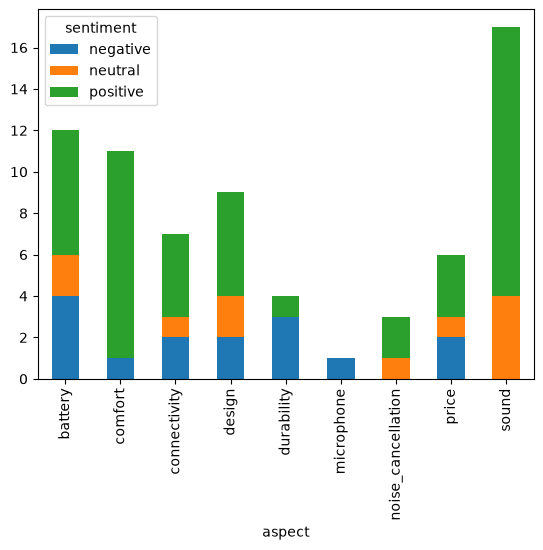

In [37]:
table = asp_df.groupby(["aspect", "sentiment"]).size().unstack(fill_value=0)
table.plot(kind="bar", stacked=True)

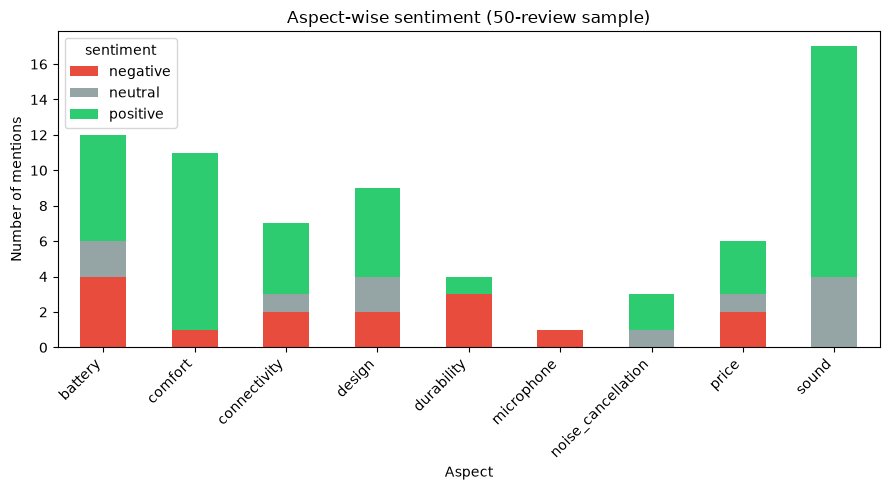

In [38]:
import matplotlib.pyplot as plt

colors = {"negative": "#e74c3c", "neutral": "#95a5a6", "positive": "#2ecc71"}
table[["negative", "neutral", "positive"]].plot(
    kind="bar", stacked=True,
    color=[colors[c] for c in ["negative", "neutral", "positive"]],
    figsize=(9, 5)
)
plt.title("Aspect-wise sentiment (50-review sample)")
plt.ylabel("Number of mentions")
plt.xlabel("Aspect")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


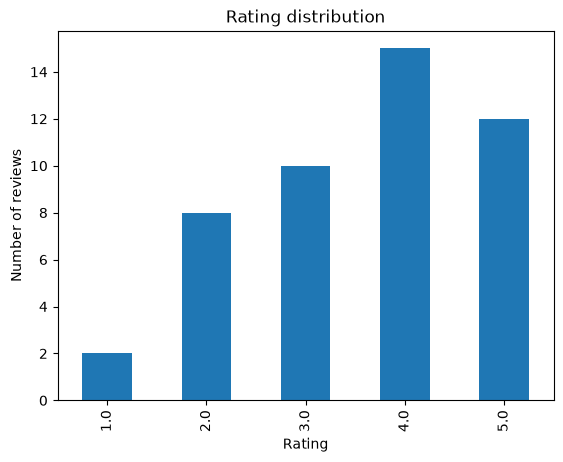

In [39]:
df["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Number of reviews")
plt.show()

In [40]:
df.groupby("sentiment")["rating"].mean()

sentiment
negative    1.714286
neutral     3.000000
positive    4.125000
Name: rating, dtype: float64

In [41]:
df.groupby("sentiment")["rating"].agg(["mean", "count"])


,mean,count
sentiment,,
negative,1.714286,7
neutral,3.000000,8
positive,4.125000,32


In [42]:
df.groupby("product_name")["rating"].agg(["mean", "count"])

,mean,count
product_name,,
AeroSound Fit,4.5,2
AirTune Pro,3.0,1
BassPod Neo,3.0,2
BassStorm Pro,3.5,2
BoomBuds X1,4.5,2
ClearTone Air,3.5,2
ClickPods Go,3.5,2
CrystalPods X,3.0,2
EchoBeat Mini,2.5,2


In [43]:
summary = df.groupby("product_name").agg(
    avg_rating=("rating", "mean"),
    reviews=("review_text", "count"),
    price=("price", "first")
)
summary.sort_values("avg_rating", ascending=False)

,avg_rating,reviews,price
product_name,,,
AeroSound Fit,4.5,2,2099.0
BoomBuds X1,4.5,2,1499.0
SoundMax Elite,4.5,2,2499.0
PowerBeat Z2,4.5,2,1899.0
PowerPods Max,4.5,2,2699.0
NovaSound Air,4.0,2,1999.0
SonicPulse S3,4.0,2,2799.0
WavePods Lite,4.0,2,1199.0
QuietBeat Pro,4.0,2,4499.0


In [44]:
summary[["price", "avg_rating"]].corr()

,price,avg_rating
price,1.000000,0.362692
avg_rating,0.362692,1.000000


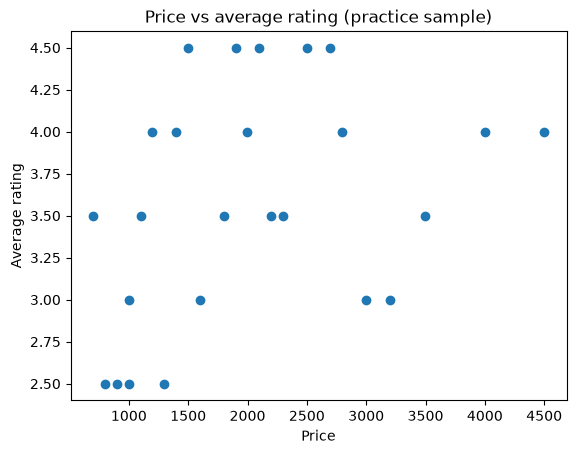

In [45]:
plt.scatter(summary["price"], summary["avg_rating"])
plt.title("Price vs average rating (practice sample)")
plt.xlabel("Price")
plt.ylabel("Average rating")
plt.show()

In [46]:
df[["review_text"]].head(18)

,review_text
0,Sound quality is great but battery drains fast
1,Very comfortable and clear sound
2,Good design but connectivity drops sometimes
3,Overpriced for what you get
4,Broke within a month
5,Good bass for the price
6,Excellent sound quality and long battery life
7,Comfortable fit but case feels cheap
8,Average sound quality for daily use
9,Battery life is disappointing


In [51]:
mine = ["neutral", "positive", "positive","negative","negative","positive","positive","positive","neutral","negative", "positive", "positive","neutral","neutral","positive","negative","positive","negative"]   # 18 labels, tumhare apne
sample["human_label"] = mine
(sample["human_label"] == sample["sentiment"]).mean()

np.float64(0.8333333333333334)

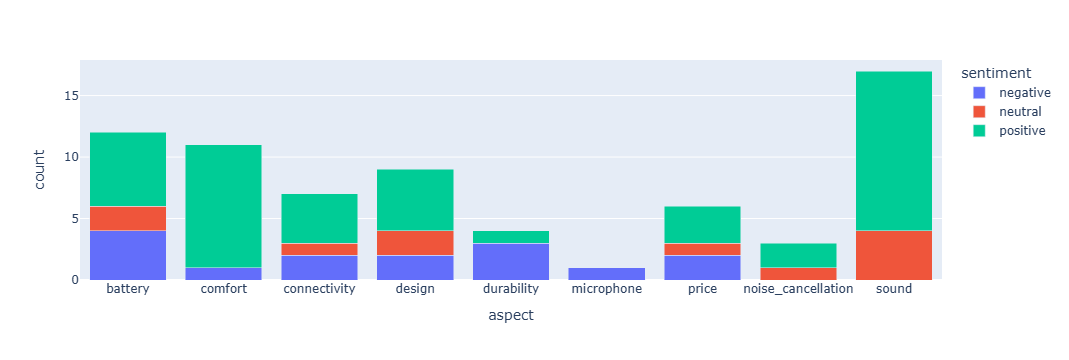

In [52]:
import plotly.express as px
table = asp_df.groupby(["aspect", "sentiment"]).size().reset_index(name="count")
fig = px.bar(table, x="aspect", y="count", color="sentiment", barmode="stack")
fig.show()

In [53]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(sample["human_label"], sample["sentiment"]))
confusion_matrix(sample["human_label"], sample["sentiment"], labels=["negative","neutral","positive"])

              precision    recall  f1-score   support

    negative       1.00      0.80      0.89         5
     neutral       0.67      0.50      0.57         4
    positive       0.82      1.00      0.90         9

    accuracy                           0.83        18
   macro avg       0.83      0.77      0.79        18
weighted avg       0.84      0.83      0.82        18



array([[4, 1, 0],
       [0, 2, 2],
       [0, 0, 9]])

In [55]:
print(classification_report(sample["human_label"], sample["sentiment"]))
confusion_matrix(sample["human_label"], sample["sentiment"], labels=["negative","neutral","positive"])

              precision    recall  f1-score   support

    negative       1.00      0.80      0.89         5
     neutral       0.67      0.50      0.57         4
    positive       0.82      1.00      0.90         9

    accuracy                           0.83        18
   macro avg       0.83      0.77      0.79        18
weighted avg       0.84      0.83      0.82        18



array([[4, 1, 0],
       [0, 2, 2],
       [0, 0, 9]])

In [56]:
df[["product_name", "price", "rating", "review_text", "compound", "sentiment"]].to_csv("../data/processed/reviews_with_sentiment.csv", index=False)
asp_df.to_csv("../data/processed/aspect_sentiment.csv", index=False)

In [51]:
rows = df["aspect_sent"].explode().dropna()
asp_df = pd.DataFrame(rows.tolist(), columns=["aspect", "score"])
asp_df["product_name"] = df.loc[rows.index, "product_name"].values
asp_df["sentiment"] = asp_df["score"].apply(label)
asp_df.to_csv("../data/processed/aspect_sentiment.csv", index=False)
asp_df.head()

,aspect,score,product_name,sentiment
0,sound,0.6249,BoomBuds X1,positive
1,battery,-0.4588,BoomBuds X1,negative
2,sound,0.7548,BoomBuds X1,positive
3,comfort,0.7548,BoomBuds X1,positive
4,design,0.4404,AirTune Pro,positive
